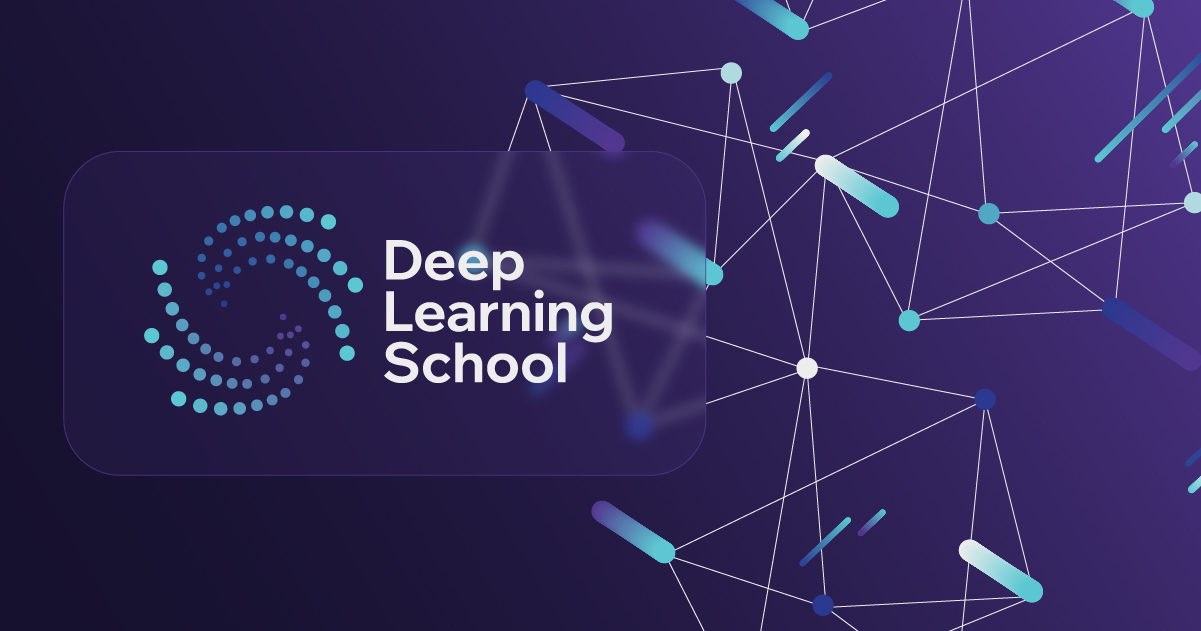


# Домашнее задание "Варианционные автоэнкодеры"

В этом домашнем задании вам предстоит реализовать несколько версий автоэнкодера для работы с изображениями.

Вы научитесь добавлять улыбку на фотографии людей, изменяя их исходное выражение лица с помощью обученной модели. А также, обучите ваш автоэнкодер генерировать изображения рукописных цифр.

# Часть 1. Vanilla Autoencoder (10 баллов)

## 1.1. Подготовка данных (1 балл)


Перед тем, как начинать работу с моделями нужно подготовить данные.

In [1]:
import math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from tqdm.notebook import tqdm

from torch.autograd import Variable
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim

from torch.utils.data import Dataset, DataLoader
import torch

from torchvision import datasets
from torchvision import transforms as transforms
from torchvision.transforms import v2

import os
import skimage.io
from skimage.transform import resize

import imageio
from PIL import Image
import kagglehub

%matplotlib inline

В этом задании вам предстоить работать с датасетом [LFW (Labeled Faces in the Wild)](https://datasets.activeloop.ai/docs/ml/datasets/lfw-dataset/#:~:text=What%20is%20LFW%20Dataset%3F,commercial%20algorithms%20prior%20to%20release).

In [2]:
# Скачиваем картинки
images_path = kagglehub.dataset_download("jessicali9530/lfw-dataset")
print("Path to dataset files:", images_path)

Path to dataset files: /kaggle/input/lfw-dataset


In [3]:
# Скачиваем атрибуты
attrs_path = kagglehub.dataset_download("averkij/lfw-attributes")
print("Path to dataset files:", attrs_path)

Path to dataset files: /kaggle/input/lfw-attributes


In [4]:
DATASET_PATH ="/kaggle/input/lfw-dataset/lfw-deepfunneled/lfw-deepfunneled/"
ATTRIBUTES_PATH = "/kaggle/input/lfw-attributes/lfw_attributes.txt"

In [5]:
def fetch_dataset(dx=80, dy=80, dimx=45, dimy=45):

    df_attrs = pd.read_csv(ATTRIBUTES_PATH, sep='\t', skiprows=1,)
    df_attrs = pd.DataFrame(df_attrs.iloc[:, :-1].values, columns = df_attrs.columns[1:])

    photo_ids = []
    for dirpath, dirnames, filenames in os.walk(DATASET_PATH):
        for fname in filenames:
            if fname.endswith(".jpg"):
                fpath = os.path.join(dirpath, fname)
                photo_id = fname[:-4].replace('_', ' ').split()
                person_id = ' '.join(photo_id[:-1])
                photo_number = int(photo_id[-1])
                photo_ids.append({'person': person_id, 'imagenum': photo_number, 'photo_path': fpath})

    photo_ids = pd.DataFrame(photo_ids)
    df = pd.merge(df_attrs, photo_ids,on=('person', 'imagenum'))

    assert len(df) == len(df_attrs), "Потеряны данные при объединении датафреймов!"

    images = df['photo_path'].apply(imageio.imread)\
                                .apply(lambda img: img[dy:-dy, dx:-dx])\
                                .apply(lambda img: np.array(Image.fromarray(img).resize([dimx, dimy])) )

    images = np.stack(images.values).astype('uint8')
    attrs = df.drop(["photo_path", "person", "imagenum"],axis=1)

    return images, attrs

In [6]:
# Обратите внимание, что датасет представляет собой не только картинки, но и атрибуты
# Атрибуты понадобятся в конце этого задания

images, attrs = fetch_dataset()

In [7]:
len(images), len(attrs)

(13143, 13143)

In [8]:
images.shape

(13143, 45, 45, 3)

In [9]:
attrs.columns

Index(['Male', 'Asian', 'White', 'Black', 'Baby', 'Child', 'Youth',
       'Middle Aged', 'Senior', 'Black Hair', 'Blond Hair', 'Brown Hair',
       'Bald', 'No Eyewear', 'Eyeglasses', 'Sunglasses', 'Mustache', 'Smiling',
       'Frowning', 'Chubby', 'Blurry', 'Harsh Lighting', 'Flash',
       'Soft Lighting', 'Outdoor', 'Curly Hair', 'Wavy Hair', 'Straight Hair',
       'Receding Hairline', 'Bangs', 'Sideburns', 'Fully Visible Forehead',
       'Partially Visible Forehead', 'Obstructed Forehead', 'Bushy Eyebrows',
       'Arched Eyebrows', 'Narrow Eyes', 'Eyes Open', 'Big Nose',
       'Pointy Nose', 'Big Lips', 'Mouth Closed', 'Mouth Slightly Open',
       'Mouth Wide Open', 'Teeth Not Visible', 'No Beard', 'Goatee',
       'Round Jaw', 'Double Chin', 'Wearing Hat', 'Oval Face', 'Square Face',
       'Round Face', 'Color Photo', 'Posed Photo', 'Attractive Man',
       'Attractive Woman', 'Indian', 'Gray Hair', 'Bags Under Eyes',
       'Heavy Makeup', 'Rosy Cheeks', 'Shiny Skin', 'Pa

In [10]:
attrs.head()

,Male,Asian,White,Black,Baby,Child,Youth,Middle Aged,Senior,Black Hair,...,Pale Skin,5 o' Clock Shadow,Strong Nose-Mouth Lines,Wearing Lipstick,Flushed Face,High Cheekbones,Brown Eyes,Wearing Earrings,Wearing Necktie,Wearing Necklace
0,1.568346,-1.889043,1.737203,-0.929729,-1.471799,-0.19558,-0.835609,-0.351468,-1.012533,-0.719593,...,0.361738,1.166118,-1.164916,-1.13999,-2.371746,-1.299932,-0.414682,-1.144902,0.694007,-0.826609
1,0.169851,-0.982408,0.422709,-1.282184,-1.36006,-0.867002,-0.452293,-0.197521,-0.956073,-0.802107,...,-0.832036,-0.39768,0.87416,-0.945431,-0.268649,-0.006244,-0.030406,-0.480128,0.66676,-0.496559
2,0.997749,-1.364195,-0.157377,-0.756447,-1.891825,-0.871526,-0.862893,0.031445,-1.341523,-0.090037,...,1.549743,1.884745,-0.999765,-1.359858,-1.912108,-1.095634,0.915126,-0.572332,0.144262,-0.841231
3,1.122719,-1.997799,1.916144,-2.514214,-2.580071,-1.404239,0.057551,0.000196,-1.273512,-1.431462,...,0.567822,-0.176089,1.108125,-1.600944,-3.264613,0.813418,0.308631,-0.848693,0.475941,-0.447025
4,1.078214,-2.008098,1.676211,-2.278056,-2.651845,-1.348408,0.649089,0.017656,-1.889111,-1.857213,...,-1.461474,-0.955283,0.119113,-1.128176,-3.161048,0.08268,-0.439614,-0.359859,-0.760774,-0.410152



Разбейте датасет изображений и атрибутов на train и val, выведите несколько картинок в output, чтобы посмотреть, как они выглядят, и приведите картинки к тензорам pytorch, чтобы можно было скормить их сети:

In [11]:
# <тут Ваш код>
train_images, val_images, train_attrs, val_attrs = train_test_split(images, attrs, test_size=0.2, shuffle=False)

In [12]:
# переводим картинки в тензоры
data_transform = transforms.ToTensor()

train_images = [data_transform(img) for img in train_images]
train_images = torch.stack(train_images)

val_images = [data_transform(img) for img in val_images]
val_images = torch.stack(val_images)

In [13]:
train_images.dtype, train_images[0].dtype

(torch.float32, torch.float32)

In [14]:
train_dataloader = DataLoader(train_images, batch_size=32)
val_dataloader = DataLoader(val_images, batch_size=32)

In [71]:
def plot_images(dataset, num_examples=6, row_figsize=(12, 3)):
    img_idx = np.random.choice(len(dataset),size=num_examples, replace=False)
    ncols = min(num_examples, 3)
    nrows = math.ceil(num_examples / ncols)
    _, axes = plt.subplots(nrows, ncols, figsize=(row_figsize[0], row_figsize[1] * nrows), tight_layout=True)
    axes = axes.ravel()

    for ix, ax in enumerate(axes):
        idx = img_idx[ix]
        img = dataset[idx].clone()
        img = torch.clamp(img, 0, 1)
        img = img.permute(1, 2, 0)
        ax.imshow(img.detach().cpu().numpy())

Отрисуем примеры картинок из трейна и валидации.

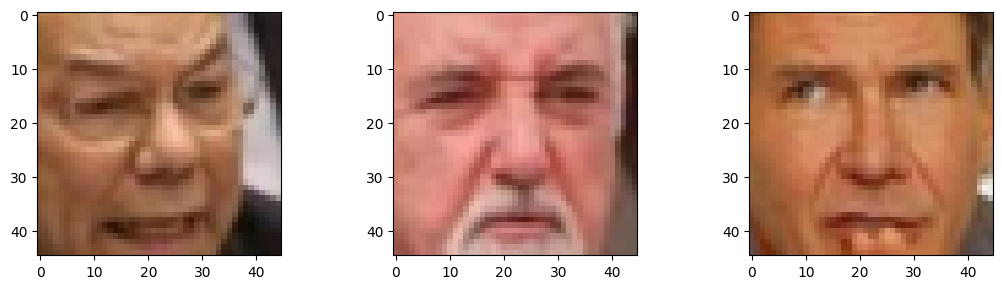

In [16]:
plot_images(train_images, num_examples=3)

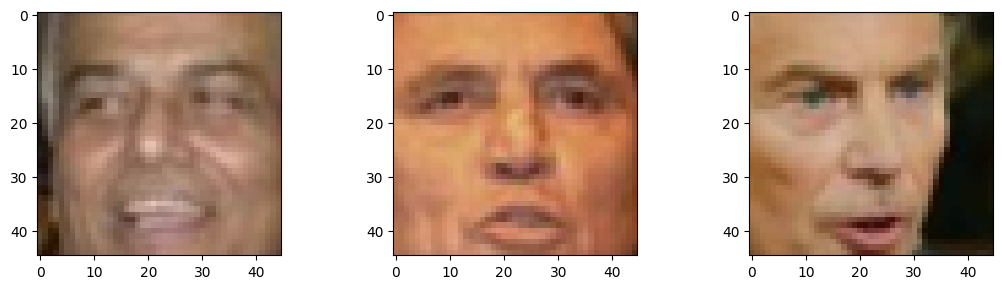

In [17]:
plot_images(val_images, num_examples=3)

## 1.2. Архитектура модели (2 балла)
В этом разделе вы напишите и обучите обычный автоэнкодер.



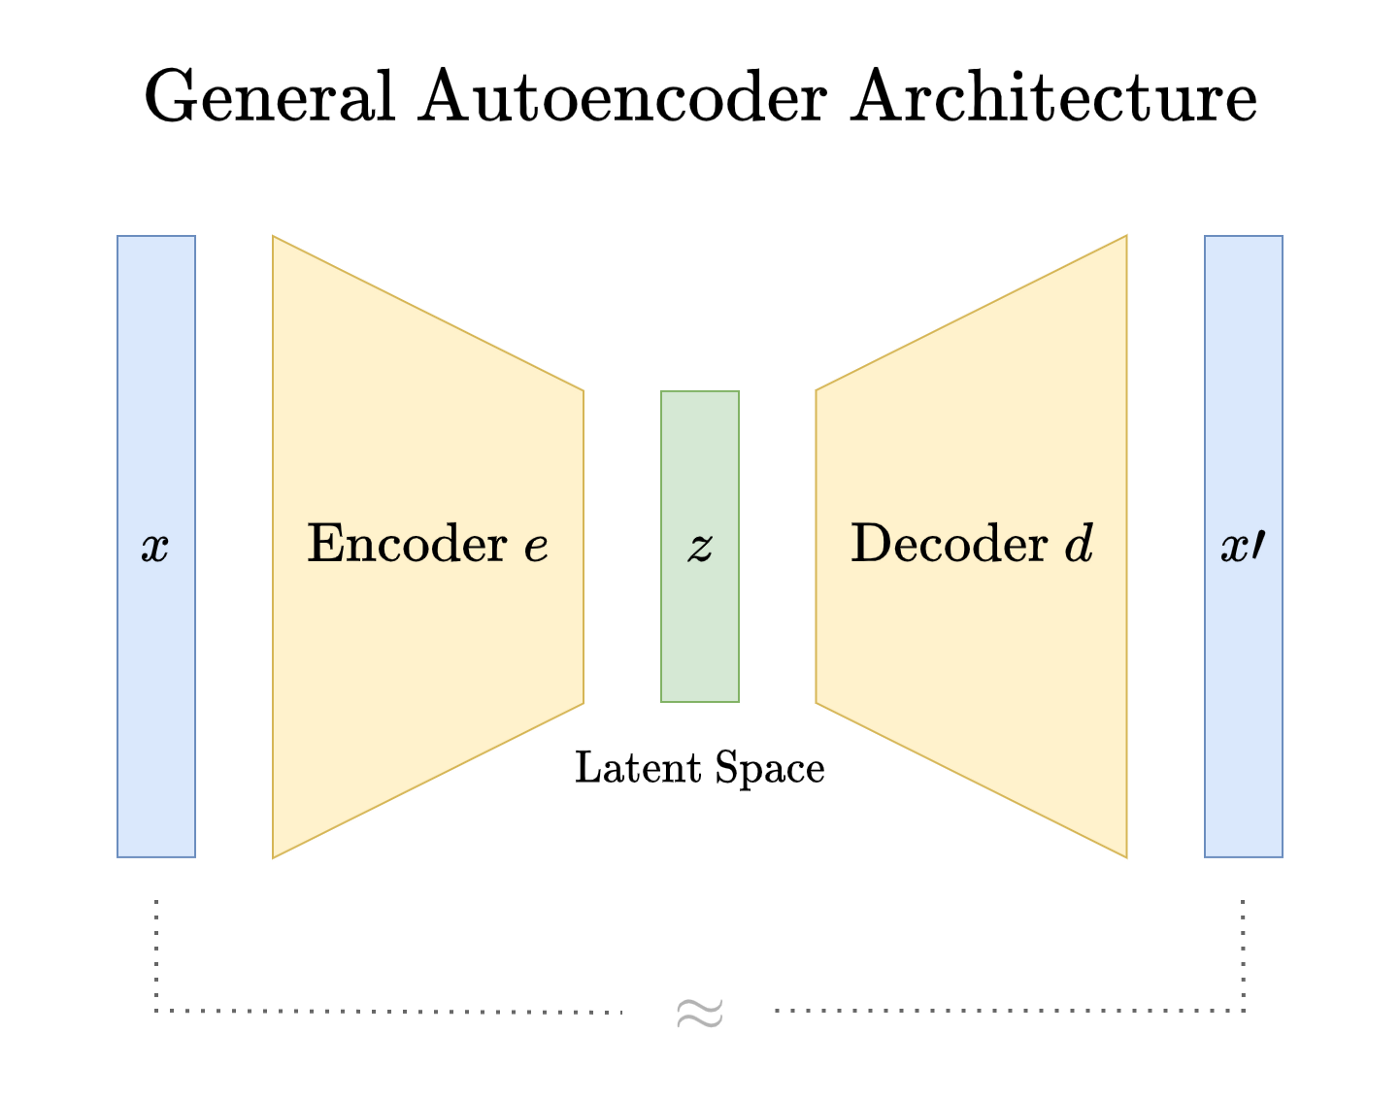

In [18]:
dim_code = 600 # выберите размер латентного вектора

In [19]:
device = 'cuda' if torch.cuda.is_available() else 'cpu'
device

'cuda'

Реализуем Autoencoder. Архитектуру (conv, fully-connected, ReLU, etc) можете выбирать сами. Экспериментируйте!

In [25]:
class Encoder(nn.Module):
    def __init__(self, hidden_dim):
        super(Encoder, self).__init__()

        self.layers = nn.Sequential(
            nn.Conv2d(in_channels=3, out_channels=64, kernel_size=7),
            nn.ReLU(inplace=True),
            nn.Conv2d(in_channels=64, out_channels=64, kernel_size=7),
            nn.ReLU(inplace=True),
            nn.Conv2d(in_channels=64, out_channels=64, kernel_size=7),
            nn.ReLU(inplace=True),
            nn.Conv2d(in_channels=64, out_channels=64, kernel_size=5),
            nn.ReLU(inplace=True),
            nn.Conv2d(in_channels=64, out_channels=64, kernel_size=5),
            nn.ReLU(inplace=True),
            nn.Conv2d(in_channels=64, out_channels=16, kernel_size=3),
            nn.ReLU(inplace=True),
            nn.Flatten(),
            nn.Linear(in_features=16*17*17, out_features=hidden_dim)
        )
    
    def forward(self, x):
        x = self.layers(x)
        return x

In [26]:
class Decoder(nn.Module):
    def __init__(self, hidden_dim):
        super(Decoder, self).__init__()

        self.linear = nn.Sequential(
            nn.Linear(in_features=hidden_dim, out_features=16*17*17),
            nn.ReLU(inplace=True)
        )
        self.layers = nn.Sequential(
            nn.ConvTranspose2d(in_channels=16, out_channels=64, kernel_size=3),
            nn.ReLU(inplace=True),
            nn.ConvTranspose2d(in_channels=64, out_channels=64, kernel_size=5),
            nn.ReLU(inplace=True),
            nn.ConvTranspose2d(in_channels=64, out_channels=64, kernel_size=5),
            nn.ReLU(inplace=True),
            nn.ConvTranspose2d(in_channels=64, out_channels=64, kernel_size=7),
            nn.ReLU(inplace=True),
            nn.ConvTranspose2d(in_channels=64, out_channels=64, kernel_size=7),
            nn.ReLU(inplace=True),
            nn.ConvTranspose2d(in_channels=64, out_channels=3, kernel_size=7)
        )

    def forward(self, x):
        x = self.linear(x)
        x = x.view(-1, 16, 17, 17)
        x = self.layers(x)
        
        return x

In [27]:
class Autoencoder(nn.Module):
    def __init__(self, hidden_dim):
        super(Autoencoder, self).__init__()
        # <определите архитектуры encoder и decoder>
        self.encoder = Encoder(hidden_dim=hidden_dim).to(device)
        self.decoder = Decoder(hidden_dim=hidden_dim).to(device)

    def forward(self, x):
        # реализуйте forward проход автоэнкодера
        # в качестве возвращаемых переменных -- латентное представление картинки (latent_code)
        # и полученная реконструкция изображения (reconstruction)
        
        latent_code = self.encoder(x)
        reconstruction = self.decoder(latent_code)
        
        return reconstruction, latent_code

In [28]:
autoencoder = Autoencoder(hidden_dim=dim_code).to(device)
optimizer = torch.optim.Adam(autoencoder.parameters(), lr=0.001)   # <Ваш любимый оптимизатор>
criterion = nn.MSELoss()

## 1.3 Обучение (2 балла)

Осталось написать код обучения автоэнкодера. При этом было бы неплохо в процессе иногда смотреть, как автоэнкодер реконструирует изображения на данном этапе обучения. Наример, после каждой эпохи (прогона train выборки через автоэнкодер) можно смотреть, какие реконструкции получились для каких-то изображений val выборки.

А, ну еще было бы неплохо выводить графики train и val лоссов в процессе тренировки =)

In [29]:
# <тут Ваш код тренировки автоэнкодера>
num_epochs = 80
train_losses = []
val_losses = []

val_reconstructions = {}
val_true = {}

latent_codes = []

for epoch in tqdm(range(num_epochs)):
    print()
    autoencoder.train()
    train_losses_per_epoch = []
    
    for X_batch in tqdm(train_dataloader, desc=f"Train"):
        X_batch = X_batch.to(device)
        
        optimizer.zero_grad()
        reconstructed, latent_code = autoencoder(X_batch)
        latent_codes.append(latent_code)
        loss = criterion(X_batch, reconstructed)
        train_losses_per_epoch.append(loss.item())
        
        loss.backward()
        optimizer.step()
        
    train_losses.append(np.mean(train_losses_per_epoch))

    autoencoder.eval()
    val_losses_per_epoch = []

    for i, X_batch in enumerate(tqdm(val_dataloader, desc=f"Validation")):
        X_batch = X_batch.to(device)

        with torch.no_grad():
            reconstructed, _ = autoencoder(X_batch)
            loss = criterion(X_batch, reconstructed)
            val_losses_per_epoch.append(loss.item())
        # добавляем реконструкции из нулевого батча
        if i == 0 and (epoch % 5 == 0 or epoch == num_epochs - 1):
            val_reconstructions[f'{epoch} epoch'] = reconstructed
            val_true[f'{epoch} epoch'] = X_batch

    val_losses.append(np.mean(val_losses_per_epoch))

    if epoch % 5 == 0:
        print(f'Epoch # {epoch}\n')
        print(f'Train loss = {train_losses[epoch]}')
        print(f'Val   loss = {val_losses[epoch]}\n')

  0%|          | 0/80 [00:00<?, ?it/s]

Train:   0%|          | 0/329 [00:00<?, ?it/s]

Validation:   0%|          | 0/83 [00:00<?, ?it/s]

Epoch # 0

Train loss = 0.040772150148917836
Val   loss = 0.020098406698061042




Train:   0%|          | 0/329 [00:00<?, ?it/s]

...

Validation:   0%|          | 0/83 [00:00<?, ?it/s]

Train:   0%|          | 0/329 [00:00<?, ?it/s]

Validation:   0%|          | 0/83 [00:00<?, ?it/s]

Train:   0%|          | 0/329 [00:00<?, ?it/s]

Validation:   0%|          | 0/83 [00:00<?, ?it/s]

Посмотрим на динамику лосса.

In [2]:
def plot_loss(train_losses, val_losses, num_epochs):
    plt.figure(figsize=(8, 5))
    plt.title('Loss dynamics')
    
    plt.plot(range(num_epochs), train_losses, label='train loss')
    plt.plot(range(num_epochs), val_losses, label='val loss', color='red')
    
    plt.xlabel('# epoch')

    plt.legend()
    plt.grid(linestyle='--')

    plt.show()

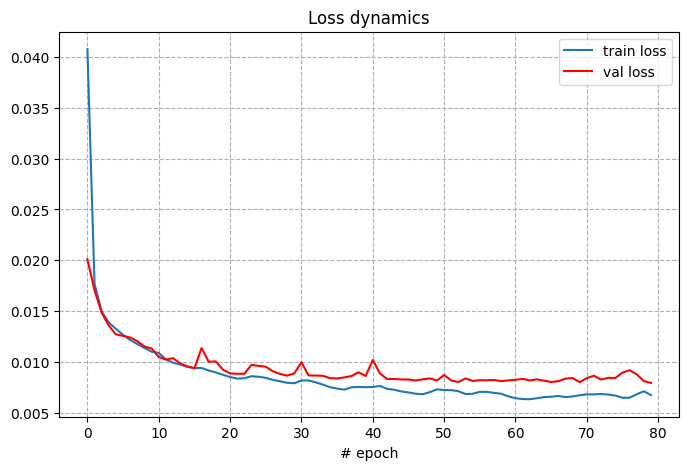

In [31]:
plot_loss(train_losses, val_losses, num_epochs)

В целом, после примерно 40 эпох лосс на валидации выходит на плато, а на трейне еще немного падает.

Давайте посмотрим, как наш тренированный автоэнкодер кодирует и восстанавливает картинки:

In [ ]:
# <тут Ваш код: выведите первые Х картинок и их реконструкций из val выборки на экран>

In [32]:
def plot_reconstruction(true_images, reconstructions, row_figsize=(12, 3)):
    num_examples = len(true_images)
    ncols = min(num_examples, 3)
    nrows = math.ceil(num_examples / ncols) * 2
    _, axes = plt.subplots(nrows, ncols, figsize=(row_figsize[0], row_figsize[1] * nrows), tight_layout=True)
    axes = axes.ravel()

    for ix, ax in enumerate(axes):
        idx = ix % num_examples
        if ix < num_examples:
            img = true_images[idx].clone()
            title = 'true'
        else:
            img = reconstructions[idx].clone()
            title = 'reconstruction'
            
        img = torch.clamp(img, 0, 1)
        img = img.permute(1, 2, 0)
        ax.imshow(img.detach().cpu().numpy())
        ax.set_title(title)

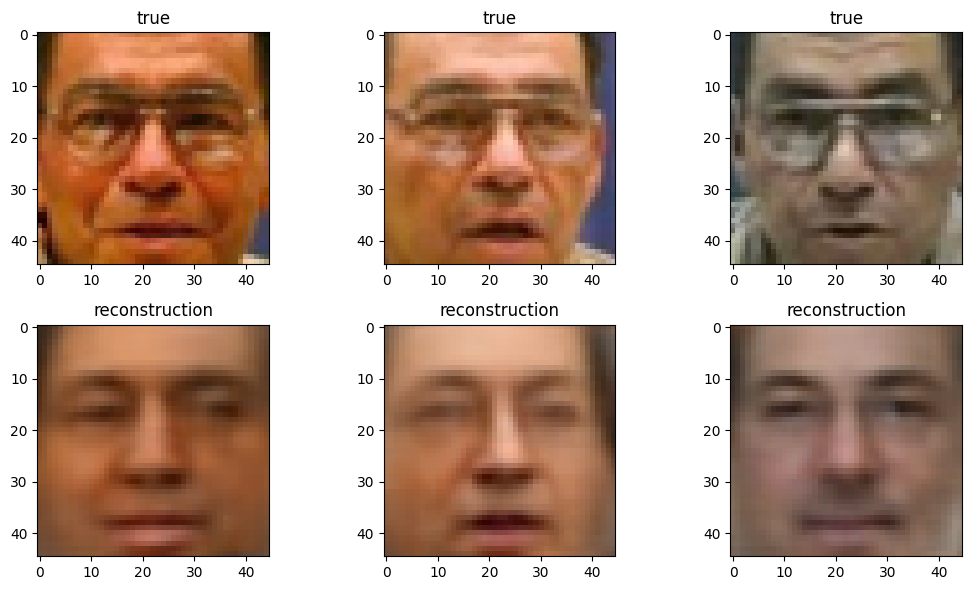

In [43]:
plot_reconstruction(val_true[f'79 epoch'][6:9], val_reconstructions[f'79 epoch'][6:9])

Что вы можете сказать про результат? $\newline$
**Ответ:** Качество оставляет желать лучшего, но что-то похожее на лица конструируется :)

## 1.4. Sampling (2 балла)

Давайте теперь будем не просто брать картинку, прогонять ее через автоэнкодер и получать реконструкцию, а попробуем создать что-то НОВОЕ!

Давайте возьмем и подсунем декодеру какие-нибудь сгенерированные нами векторы (например, из нормального распределения) и посмотрим на результат реконструкции декодера:

__Подсказка:__ Если вместо лиц у вас выводится непонятно что, попробуйте посмотреть, как выглядят латентные векторы картинок из датасета. Так как в обучении нейронных сетей есть определенная доля рандома, векторы латентного слоя могут быть распределены НЕ как `np.random.randn(25, <latent_space_dim>)`. А чтобы у нас получались лица при запихивании вектора декодеру, вектор должен быть распределен так же, как латентные векторы реальных фоток. Так что в таком случае придется рандом немного подогнать.

Посмотрим на распределение латентных векторов.

In [48]:
train_latent_codes = torch.cat(latent_codes, dim=0)

In [49]:
latent_codes_mean = torch.mean(train_latent_codes, dim=0)
latent_codes_std = torch.std(train_latent_codes, dim=0)

In [50]:
latent_codes_mean.shape, latent_codes_std.shape

(torch.Size([600]), torch.Size([600]))

In [55]:
# сгенерируем 25 рандомных векторов размера latent_space
z = np.random.randn(25, dim_code)
z = torch.tensor(z, dtype=torch.float32, device=device)

# подгоняем под распределение латентных векторов
z = z * latent_codes_std + latent_codes_mean
output = autoencoder.decoder(z)

In [3]:
# отрисовывает первые nrows * ncols изображений
def plot_examples(dataset, ncols, nrows, figsize=(10, 3)):
    _, axes = plt.subplots(nrows, ncols, figsize=(figsize[0], figsize[1] * nrows), tight_layout=True)
    axes = axes.ravel()

    for ix, ax in enumerate(axes):
        img = dataset[ix]
        img = torch.clamp(img, 0, 1)
        img = img.permute(1, 2, 0)
        ax.imshow(img.detach().cpu().numpy())

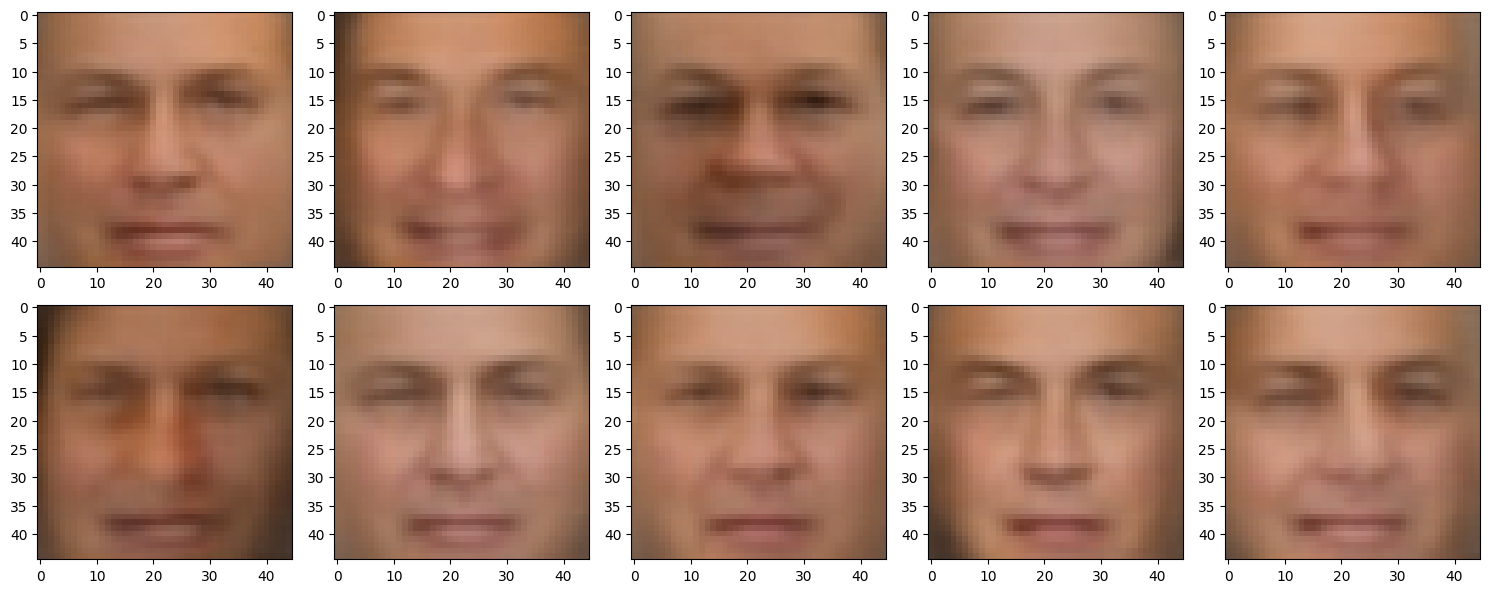

In [85]:
plot_examples(output, ncols=5, nrows=2, figsize=(15, 3))

Ура! Получилось что-то похожее на лица

## 1.5 Time to make fun! (3 балла)

Давайте научимся пририсовывать людям улыбки =)

<img src="https://i.imgur.com/tOE9rDK.png" alt="linear" width="700" height="400">

План такой:

1. Нужно выделить "вектор улыбки": для этого нужно из выборки изображений найти несколько (~15) людей с улыбками и столько же без.

Найти людей с улыбками вам поможет файл с атрибутами, скачанный вместе с картинками. В нем указаны имена изображений и присутствубщие атрибуты (улыбки, очки и прочее интересное).

2. Вычислить латентный вектор для всех улыбающихся людей (прогнать их через encoder) и то же для всех грустненьких.

3. Вычислить, собственно, вектор улыбки -- посчитать разность между средним латентным вектором улыбающихся людей и средним латентным вектором грустных людей.

4. А теперь приделаем улыбку грустному человеку: добавим полученный в пункте 3 вектор к латентному вектору грустного человека и прогоним полученный вектор через decoder. Получим того же человека, но уже не грустненького!

In [106]:
# <ваш код здесь>
num_people = 15
smiling_idx = list(attrs.sort_values(by='Smiling', ascending=False).head(num_people).index)
print(smiling_idx)

[8643, 1816, 13034, 5624, 1045, 4681, 6139, 11797, 1359, 2031, 1955, 9004, 459, 6166, 682]


In [96]:
sad_idx = list(attrs.sort_values(by='Smiling', ascending=True).head(num_people).index)
print(sad_idx)

[11571, 1234, 7506, 5458, 7065, 11912, 1654, 471, 8410, 8596, 12688, 1432, 10097, 10506, 9114]


In [97]:
smiling_images = images[smiling_idx]
sad_images = images[sad_idx]

In [98]:
smiling_images = [data_transform(img) for img in smiling_images]
smiling_images = torch.stack(smiling_images)

sad_images = [data_transform(img) for img in sad_images]
sad_images = torch.stack(sad_images)

In [99]:
smiling_images.dtype, smiling_images[0].dtype

(torch.float32, torch.float32)

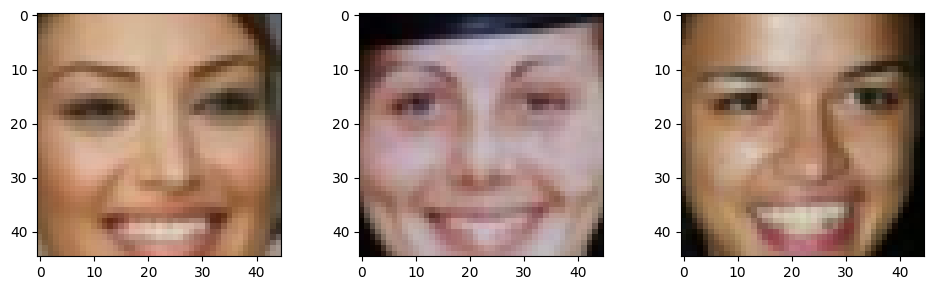

In [127]:
plot_examples(smiling_images[9:], ncols=3, nrows=1)

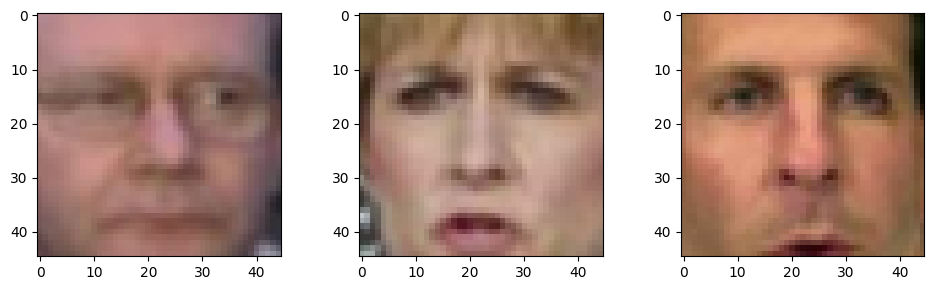

In [126]:
plot_examples(sad_images[9:], ncols=3, nrows=1)

In [102]:
smiling_dataloader = DataLoader(smiling_images, shuffle=False)
sad_dataloader = DataLoader(sad_images, shuffle=False)

In [103]:
# вычисляем вектор улыбки
autoencoder.eval()

latent_smiling = []
latent_sad = []

with torch.no_grad():
    for X_batch in smiling_dataloader:
        X_batch = X_batch.to(device)
        latent = autoencoder.encoder(X_batch)
        latent_smiling.append(latent)
    
    for X_batch in sad_dataloader:
        X_batch = X_batch.to(device)
        latent = autoencoder.encoder(X_batch)
        latent_sad.append(latent)

latent_smiling = torch.cat(latent_smiling, dim=0)
latent_sad = torch.cat(latent_sad, dim=0)

latent_smiling_mean = torch.mean(latent_smiling, dim=0)
latent_sad_mean = torch.mean(latent_sad, dim=0)

smile_vec = latent_smiling_mean - latent_sad_mean

In [104]:
smile_vec.shape

torch.Size([600])

In [129]:
# меняем латентные вектора грустным людям
alpha = 0.8
update_sad = latent_sad.clone()
for i in range(num_people):
    update_sad[i] = latent_sad[i] + alpha * smile_vec

In [133]:
# добавляем улыбки
autoencoder.eval()

sad_original = []
sad_reconstruction = []
ord_reconstruction = []

with torch.no_grad():
    for i, X_batch in enumerate(sad_dataloader):
        reconstruction = autoencoder.decoder(update_sad[i])
        sad_reconstruction.append(reconstruction)
        sad_original.append(X_batch)

sad_original = torch.cat(sad_original)
sad_reconstruction = torch.cat(sad_reconstruction)

In [134]:
sad_reconstruction.shape

torch.Size([15, 3, 45, 45])

Отрисуем людей с улыбкой:

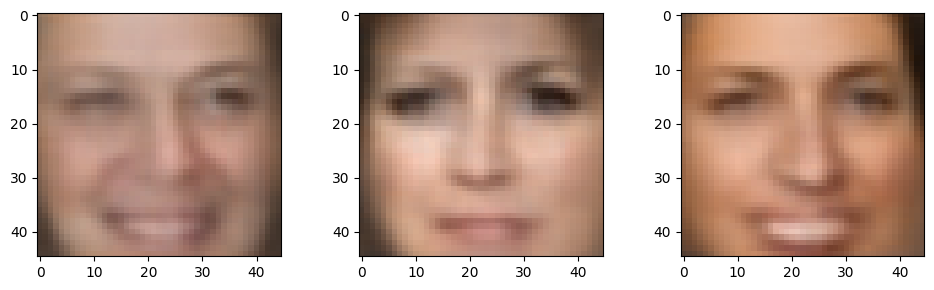

In [135]:
plot_examples(sad_reconstruction[9:], ncols=3, nrows=1)

Так как топ-15 улыбающихся людей это женщины, а ~85 % грустных -- мужчины, то при добавлении вектора улыбки они становятся более женственными.

Вуаля! Вы восхитительны!

Теперь вы можете пририсовывать людям не только улыбки, но и много чего другого -- закрывать/открывать глаза, пририсовывать очки... В общем, все, на что хватит фантазии и на что есть атрибуты в `attrs`:)

# Часть 2: Variational Autoencoder (10 баллов)

Займемся обучением вариационных автоэнкодеров — проапгрейженной версии AE. Обучать будем на датасете MNIST, содержащем написанные от руки цифры от 0 до 9

In [4]:
batch_size = 32
# MNIST Dataset
train_dataset = datasets.MNIST(root='./mnist_data/', train=True, transform=transforms.ToTensor(), download=True)
test_dataset = datasets.MNIST(root='./mnist_data/', train=False, transform=transforms.ToTensor(), download=False)

# Data Loader (Input Pipeline)
train_loader = torch.utils.data.DataLoader(dataset=train_dataset, batch_size=batch_size, shuffle=True)
test_loader = torch.utils.data.DataLoader(dataset=test_dataset, batch_size=batch_size, shuffle=False)

100%|██████████| 9.91M/9.91M [00:00<00:00, 38.2MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 1.06MB/s]
100%|██████████| 1.65M/1.65M [00:00<00:00, 9.54MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 8.62MB/s]


In [5]:
len(train_dataset), len(test_dataset)

(60000, 10000)

In [6]:
train_loader.dataset[0][0].shape

torch.Size([1, 28, 28])

## 2.1 Архитектура модели и обучение (2 балла)

Реализуем VAE. Архитектуру (conv, fully-connected, ReLU, etc) можете выбирать сами. Рекомендуем пользоваться более сложными моделями, чем та, что была на семинаре :) Экспериментируйте!

In [7]:
latent_dim = 64

In [8]:
class VAE(nn.Module):
    def __init__(self):
        # <определите архитектуры encoder и decoder
        # помните, у encoder должны быть два "хвоста",
        # т.е. encoder должен кодировать картинку в 2 переменные -- mu и logsigma>
        
        super(VAE, self).__init__()
        
        self.encoder = nn.Sequential(
            nn.Conv2d(in_channels=1, out_channels=16, kernel_size=4),
            nn.ReLU(inplace=True),
            nn.Conv2d(in_channels=16, out_channels=16, kernel_size=4),
            nn.ReLU(inplace=True),
            nn.Conv2d(in_channels=16, out_channels=16, kernel_size=3),
            nn.ReLU(inplace=True),
            nn.Conv2d(in_channels=16, out_channels=16, kernel_size=3),
            nn.ReLU(inplace=True),
            nn.Flatten(),
            nn.Linear(in_features=16*18*18, out_features=2 * latent_dim)
        )

        self.decoder = nn.ModuleList()
        
        linear_part = nn.Sequential(
            nn.Linear(in_features=latent_dim, out_features=16*18*18),
            nn.ReLU(inplace=True),
        )
        conv_part = nn.Sequential(
            nn.ConvTranspose2d(in_channels=16, out_channels=16, kernel_size=3),
            nn.ReLU(inplace=True),
            nn.ConvTranspose2d(in_channels=16, out_channels=16, kernel_size=3),
            nn.ReLU(inplace=True),
            nn.ConvTranspose2d(in_channels=16, out_channels=16, kernel_size=4),
            nn.ReLU(inplace=True),
            nn.ConvTranspose2d(in_channels=16, out_channels=1, kernel_size=4)
        )
        
        self.decoder.append(linear_part)
        self.decoder.append(conv_part)

    def encode(self, x):
        # <реализуйте forward проход энкодера
        # в качестве ваозвращаемых переменных -- mu и logsigma>
        
        x = self.encoder(x)
        x = x.view(-1, 2, latent_dim)
        mu = x[:, 0, :]
        logsigma = x[:, 1, :]
        
        return mu, logsigma

    def gaussian_sampler(self, mu, logsigma):
        if self.training:
            # <засемплируйте латентный вектор из нормального распределения с параметрами mu и sigma>
            std = torch.exp(0.5 * logsigma)
            eps = torch.randn_like(std)
            sample = std * eps + mu
            return sample
        else:
            # на инференсе возвращаем не случайный вектор из нормального распределения, а центральный -- mu.
            # на инференсе выход автоэнкодера должен быть детерминирован.
            return mu

    def decode(self, z):
        # <реализуйте forward проход декодера
        # в качестве возвращаемой переменной -- reconstruction>

        for i, layer in enumerate(self.decoder):
            if i == 1:
                z = z.view(-1, 16, 18, 18)
            z = layer(z)
        reconstruction = torch.sigmoid(z)
        
        return reconstruction

    def forward(self, x):
        # <используя encode и decode, реализуйте forward проход автоэнкодера
        # в качестве ваозвращаемых переменных -- mu, logsigma и reconstruction>

        mu, logsigma = self.encode(x)
        z = self.gaussian_sampler(mu, logsigma)
        reconstruction = self.decode(z)
        
        return mu, logsigma, reconstruction

Определим лосс и его компоненты для VAE:

Надеюсь, вы уже прочитали материал в towardsdatascience (или еще где-то) про VAE и знаете, что лосс у VAE состоит из двух частей: KL и log-likelihood.

Общий лосс будет выглядеть так:

$$\mathcal{L} = -D_{KL}(q_{\phi}(z|x)||p(z)) + \log p_{\theta}(x|z)$$

Формула для KL-дивергенции:

$$D_{KL} = -\frac{1}{2}\sum_{i=1}^{dimZ}(1+log(\sigma_i^2)-\mu_i^2-\sigma_i^2)$$

В качестве log-likelihood возьмем привычную нам кросс-энтропию.

In [9]:
def KL_divergence(mu, logsigma):
    """
    часть функции потерь, которая отвечает за "близость" латентных представлений разных цифр
    """
     # <напишите код для KL-дивергенции, пользуясь формулой выше>
    loss = -0.5 * torch.sum(1 + logsigma - mu ** 2 - torch.exp(logsigma))
    return loss

def log_likelihood(x, reconstruction):
    """
    часть функции потерь, которая отвечает за качество реконструкции (как mse в обычном autoencoder)
    """
    loss = nn.BCELoss(reduction='sum')
    return loss(reconstruction, x)

def loss_vae(x, mu, logsigma, reconstruction):
    # <соедините тут две компоненты лосса. Mind the sign!>
    return KL_divergence(mu, logsigma) + log_likelihood(x, reconstruction)

И обучим модель:

In [10]:
device = 'cuda' if torch.cuda.is_available() else 'cpu'
device

'cuda'

In [11]:
autoencoder = VAE().to(device)
optimizer = torch.optim.Adam(autoencoder.parameters(), lr=0.001)
criterion = loss_vae

In [12]:
# <обучите модель на датасете MNIST>
num_epochs = 50
train_losses = []
val_losses = []

for epoch in tqdm(range(num_epochs)):
    autoencoder.train()
    train_losses_per_epoch = []
    
    print(f'Epoch # {epoch}')
    
    for X_batch, _ in tqdm(train_loader, desc=f'Train'):
        X_batch = X_batch.to(device)
        
        optimizer.zero_grad()
        mu, logsigma, reconstruction = autoencoder(X_batch)
        reconstruction = reconstruction.view(-1, 1, 28, 28)
        
        loss = criterion(X_batch, mu, logsigma, reconstruction)
        train_losses_per_epoch.append(loss.item())
        loss.backward()

        optimizer.step()

    train_losses.append(np.mean(train_losses_per_epoch))

    autoencoder.eval()
    val_losses_per_epoch = []
    
    for i, (X_batch, _) in enumerate(tqdm(test_loader, desc=f'Validation')):
        X_batch = X_batch.to(device)

        with torch.no_grad():
            mu, logsigma, reconstruction = autoencoder(X_batch)
            reconstruction = reconstruction.view(-1, 1, 28, 28)
            
            loss = criterion(X_batch, mu, logsigma, reconstruction)
            val_losses_per_epoch.append(loss.item())  
            
    val_losses.append(np.mean(val_losses_per_epoch))

    if epoch % 5 == 0:
        print(f'Train loss = {train_losses[epoch]}')
        print(f'Val   loss = {val_losses[epoch]}\n')

  0%|          | 0/50 [00:00<?, ?it/s]

Epoch # 0


Train:   0%|          | 0/1875 [00:00<?, ?it/s]

Validation:   0%|          | 0/313 [00:00<?, ?it/s]

Train loss = 4365.1767002604165
Val   loss = 3155.4480510870108

Epoch # 1


...

Train:   0%|          | 0/1875 [00:00<?, ?it/s]

Validation:   0%|          | 0/313 [00:00<?, ?it/s]

Epoch # 49


Train:   0%|          | 0/1875 [00:00<?, ?it/s]

Validation:   0%|          | 0/313 [00:00<?, ?it/s]

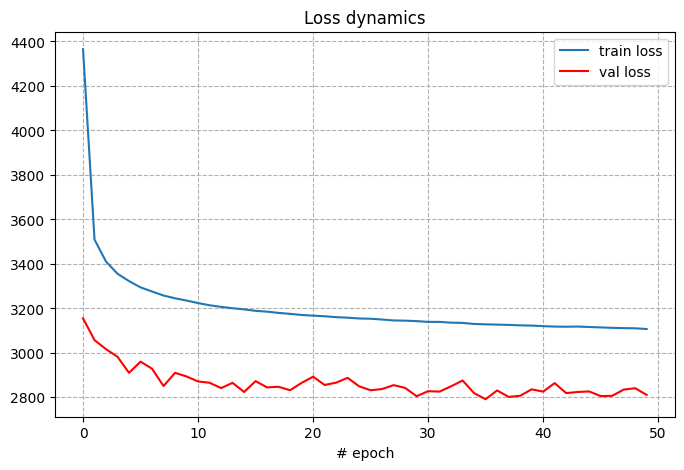

In [13]:
plot_loss(train_losses, val_losses, num_epochs)

Давайте посмотрим, как наш тренированный VAE кодирует и восстанавливает картинки:

In [14]:
# < тут Ваш код: выведите первые Х картинок и их реконструкций из val выборки на экран>

autoencoder.eval()
with torch.no_grad():
    for X_batch, y in tqdm(test_loader):
        X_batch = X_batch.to(device)

        mu, logsigma, reconstruction = autoencoder(X_batch)
        result = reconstruction
        ground_truth = X_batch

  0%|          | 0/313 [00:00<?, ?it/s]

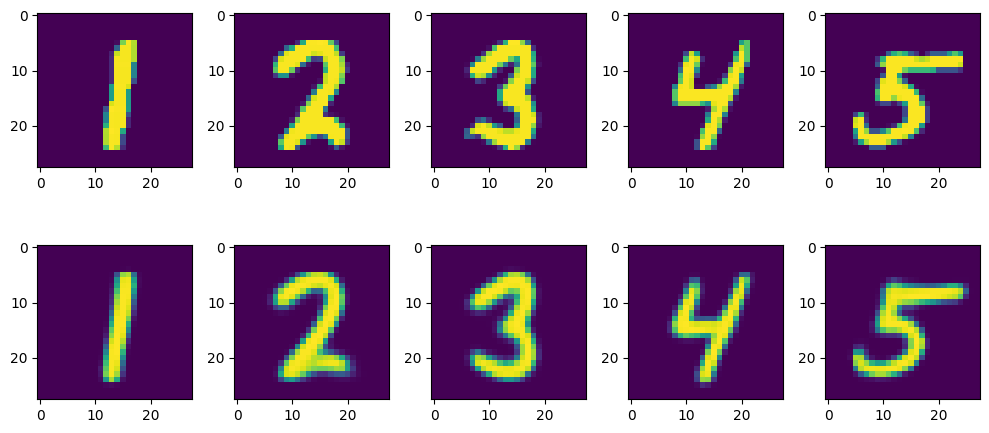

In [15]:
plot_examples(torch.cat([ground_truth[:5], result[:5]]), ncols=5, nrows=2)

Давайте попробуем проделать для VAE то же, что и с обычным автоэнкодером -- подсунуть decoder'у из VAE случайные векторы из нормального распределения и посмотреть, какие картинки получаются:

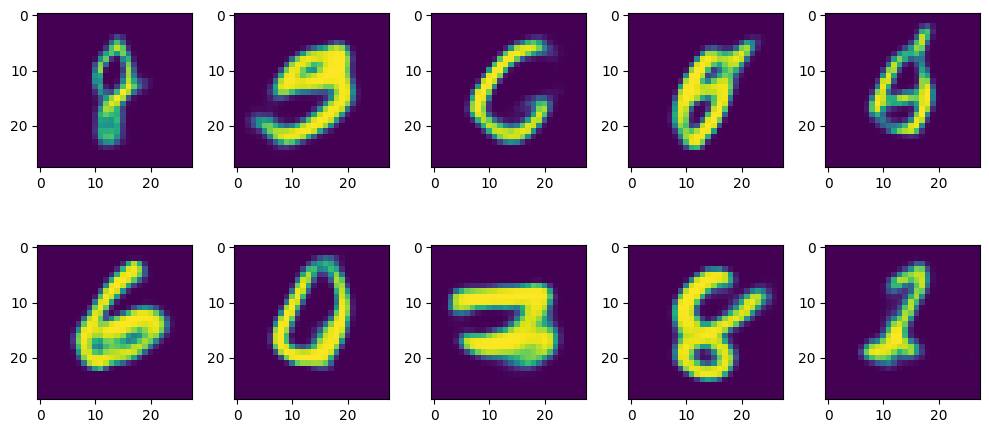

In [18]:
# вспомните про замечание из этого же пункта обычного AE про распределение латентных переменных
z = np.array([np.random.normal(0, 1, latent_dim) for i in range(10)])
z = torch.tensor(z, device=device, dtype=torch.float)
output = autoencoder.decode(z)

# <выведите тут полученные картинки>
plot_examples(output, ncols=5, nrows=2)

Видно, что генерируются изображения, в которых можно разглядеть цифры.

## 2.2. Latent Representation (2 балла)

Давайте посмотрим, как латентные векторы картинок цифр выглядят в пространстве.
Ваша задача -- изобразить латентные векторы картинок точками в двумерном просторанстве.

Это позволит оценить, насколько плотно распределены латентные векторы изображений цифр в пространстве.

Плюс давайте сделаем такую вещь: покрасим точки, которые соответствуют картинкам каждой цифры, в свой отдельный цвет

Подсказка: красить -- это просто =) У plt.scatter есть параметр c (color), см. в документации.


Итак, план:
1. Получить латентные представления картинок тестового датасета
2. С помощью `TSNE` (есть в `sklearn`) сжать эти представления до размерности 2 (чтобы можно было их визуализировать точками в пространстве)
3. Визуализировать полученные двумерные представления с помощью `matplotlib.scatter`, покрасить разными цветами точки, соответствующие картинкам разных цифр.

In [19]:
from sklearn.manifold import TSNE

In [121]:
# <ваш код получения латентных представлений, применения TSNE и визуализации>

all_latents = []
all_targets = []

autoencoder.eval()

with torch.no_grad():
    for X_batch, y_batch in tqdm(test_loader):
        X_batch = X_batch.to(device)
        y_batch = y_batch.to(device)
        
        mu, logsigma, reconstruction = autoencoder(X_batch)
        
        latent_vec = torch.randn(latent_dim, device=device)
        std = torch.exp(logsigma)
        latent_vec = std * latent_vec + mu
        all_latents.append(latent_vec.detach().cpu())
        all_targets.append(y_batch.detach().cpu())

all_latents = torch.cat(all_latents, dim=0).numpy()
all_targets = torch.cat(all_targets, dim=0).numpy()

  0%|          | 0/313 [00:00<?, ?it/s]

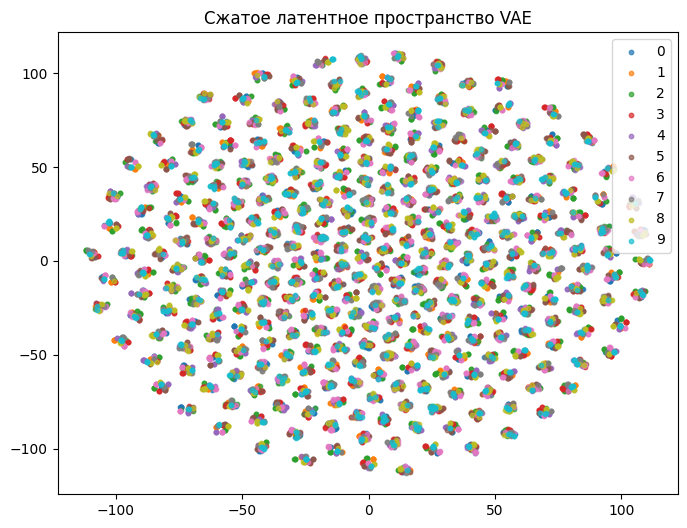

In [122]:
tsne = TSNE(n_components=2, perplexity=7, random_state=42)
all_latents_emb = tsne.fit_transform(all_latents)

plt.figure(figsize=(8, 6))
plt.title('Сжатое латентное пространство VAE')

classes = np.unique(all_targets)
for cls in classes:
    idx = all_targets == cls
    plt.scatter(all_latents_emb[idx, 0], all_latents_emb[idx, 1], label=f"{cls}", s=10, alpha=0.7)

plt.legend()
plt.show()

Что вы думаете о виде латентного представления?

__Congrats v2.0!__

## 2.3. Conditional VAE (6 баллов)


Мы уже научились обучать обычный AE на датасете картинок и получать новые картинки, используя генерацию шума и декодер.
Давайте теперь допустим, что мы обучили AE на датасете MNIST и теперь хотим генерировать новые картинки с числами с помощью декодера (как выше мы генерили рандомные лица).
И вот нам понадобилось сгенерировать цифру 8, и мы подставляем разные варианты шума, но восьмерка никак не генерится:(

Хотелось бы добавить к нашему AE функцию "выдай мне рандомное число из вот этого вот класса", где классов десять (цифры от 0 до 9 образуют десять классов).  Conditional AE — так называется вид автоэнкодера, который предоставляет такую возможность. Ну, название "conditional" уже говорит само за себя.

И в этой части задания мы научимся такие обучать.

### Архитектура

На картинке ниже представлена архитектура простого Conditional VAE.

По сути, единственное отличие от обычного -- это то, что мы вместе с картинкой в первом слое энкодера и декодера передаем еще информацию о классе картинки.

То есть, в первый (входной) слой энкодера подается конкатенация картинки и информации о классе (например, вектора из девяти нулей и одной единицы). В первый слой декодера подается конкатенация латентного вектора и информации о классе.


![alt text](https://sun9-63.userapi.com/impg/Mh1akf7mfpNoprrSWsPOouazSmTPMazYYF49Tw/djoHNw_9KVA.jpg?size=1175x642&quality=96&sign=e88baec5f9bb91c8443fba31dcf0a4df&type=album)

![alt text](https://sun9-73.userapi.com/impg/UDuloLNKhzTBYAKewgxke5-YPsAKyGOqA-qCRg/MnyCavJidxM.jpg?size=1229x651&quality=96&sign=f2d21bfacc1c5755b76868dc4cfef39c&type=album)



На всякий случай: это VAE, то есть, latent у него все еще состоит из mu и sigma

Таким образом, при генерации новой рандомной картинки мы должны будем передать декодеру сконкатенированные латентный вектор и класс картинки.

P.S. Также можно передавать класс картинки не только в первый слой, но и в каждый слой сети. То есть на каждом слое конкатенировать выход из предыдущего слоя и информацию о классе.

In [80]:
class CVAE(nn.Module):
    def __init__(self, num_classes):
        # <определите архитектуры encoder и decoder
        # помните, у encoder должны быть два "хвоста",
        # т.е. encoder должен кодировать картинку в 2 переменные -- mu и logsigma>
        super(CVAE, self).__init__()
        self.num_classes = num_classes
        
        self.encoder = nn.ModuleList()

        first_part = nn.Sequential(
            nn.Conv2d(in_channels=1 + num_classes, out_channels=16, kernel_size=4),
            nn.ReLU(inplace=True),
        )
        second_part = nn.Sequential(
            nn.Conv2d(in_channels=16, out_channels=16, kernel_size=4),
            nn.ReLU(inplace=True),
            nn.Conv2d(in_channels=16, out_channels=16, kernel_size=3),
            nn.ReLU(inplace=True),
            nn.Conv2d(in_channels=16, out_channels=16, kernel_size=3),
            nn.ReLU(inplace=True),
            nn.Flatten(),
            nn.Linear(in_features=16*18*18, out_features=2 * latent_dim)
        )
        
        self.encoder.append(first_part)
        self.encoder.append(second_part)

        self.decoder = nn.ModuleList()
        
        linear_part = nn.Sequential(
            nn.Linear(in_features=latent_dim + num_classes, out_features=16*18*18),
            nn.ReLU(inplace=True),
        )
        conv_part = nn.Sequential(
            nn.ConvTranspose2d(in_channels=16, out_channels=16, kernel_size=3),
            nn.ReLU(inplace=True),
            nn.ConvTranspose2d(in_channels=16, out_channels=16, kernel_size=3),
            nn.ReLU(inplace=True),
            nn.ConvTranspose2d(in_channels=16, out_channels=16, kernel_size=4),
            nn.ReLU(inplace=True),
            nn.ConvTranspose2d(in_channels=16, out_channels=1, kernel_size=4)
        )
        
        self.decoder.append(linear_part)
        self.decoder.append(conv_part)

    def encode(self, x, target):
        # <реализуйте forward проход энкодера
        # в качестве возвращаемых переменных -- mu, logsigma и класс картинки>

        B, C, H, W = x.shape

        target = target.long()
        y = F.one_hot(target, num_classes=self.num_classes).float()
        
        y = y.view(B, self.num_classes, 1, 1)
        y = y.expand(B, self.num_classes, H, W)

        xy = torch.cat([x, y], dim=1)
        x = self.encoder[0](xy)
        x = self.encoder[1](x)

        x = x.view(-1, 2, latent_dim)
        mu = x[:, 0, :]
        logsigma = x[:, 1, :]

        return mu, logsigma, target

    def gaussian_sampler(self, mu, logsigma):
        if self.training:
            # <засемплируйте латентный вектор из нормального распределения с параметрами mu и sigma>
            std = torch.exp(0.5 * logsigma)
            eps = torch.randn_like(std)
            sample = std * eps + mu
            return sample
        else:
            # на инференсе возвращаем не случайный вектор из нормального распределения, а центральный -- mu.
            # на инференсе выход автоэнкодера должен быть детерминирован.
            return mu

    def decode(self, z, target):
        # <реализуйте forward проход декодера
        # в качестве возвращаемой переменной -- reconstruction>

        target = target.long()
        y = F.one_hot(target, num_classes=self.num_classes).float()
        
        zy = torch.cat([z, y], dim=1)

        z = self.decoder[0](zy)
        z = z.view(-1, 16, 18, 18)
        z = self.decoder[1](z)
        reconstruction = torch.sigmoid(z)

        return reconstruction

    def forward(self, x, target):
        # используя encode и decode, реализуйте forward проход автоэнкодера
        # в качестве ваозвращаемых переменных -- mu, logsigma и reconstruction
        mu, logsigma, target = self.encode(x, target)
        z = self.gaussian_sampler(mu, logsigma)
        reconstruction = self.decode(z, target)
        
        return mu, logsigma, reconstruction

In [81]:
autoencoder = CVAE(num_classes=10).to(device)
optimizer = torch.optim.Adam(autoencoder.parameters(), lr=0.001)
criterion = loss_vae

In [82]:
# <обучите модель на датасете MNIST>
num_epochs = 50
train_losses = []
val_losses = []

for epoch in tqdm(range(num_epochs)):
    autoencoder.train()
    train_losses_per_epoch = []
    
    print(f'Epoch # {epoch}')
    
    for X_batch, y_batch in tqdm(train_loader, desc=f'Train'):
        X_batch = X_batch.to(device)
        y_batch = y_batch.to(device)
        
        optimizer.zero_grad()
        mu, logsigma, reconstruction = autoencoder(X_batch, y_batch)
        
        loss = criterion(X_batch, mu, logsigma, reconstruction)
        train_losses_per_epoch.append(loss.item())
        loss.backward()

        optimizer.step()

    train_losses.append(np.mean(train_losses_per_epoch))

    autoencoder.eval()
    val_losses_per_epoch = []
    
    for i, (X_batch, y_batch) in enumerate(tqdm(test_loader, desc=f'Validation')):
        X_batch = X_batch.to(device)
        y_batch = y_batch.to(device)

        with torch.no_grad():
            mu, logsigma, reconstruction = autoencoder(X_batch, y_batch)
            
            loss = criterion(X_batch, mu, logsigma, reconstruction)
            val_losses_per_epoch.append(loss.item())  
            
    val_losses.append(np.mean(val_losses_per_epoch))

    if epoch % 5 == 0 or epoch == num_epochs - 1:
        print(f'Train loss = {train_losses[epoch]}')
        print(f'Val   loss = {val_losses[epoch]}\n')

  0%|          | 0/50 [00:00<?, ?it/s]

Epoch # 0


Train:   0%|          | 0/1875 [00:00<?, ?it/s]

Validation:   0%|          | 0/313 [00:00<?, ?it/s]

Train loss = 4456.441785416667
Val   loss = 3191.220663344898

Epoch # 1


...

Validation:   0%|          | 0/313 [00:00<?, ?it/s]

Epoch # 49


Train:   0%|          | 0/1875 [00:00<?, ?it/s]

Validation:   0%|          | 0/313 [00:00<?, ?it/s]

Train loss = 2963.740369140625
Val   loss = 2709.6578166340105



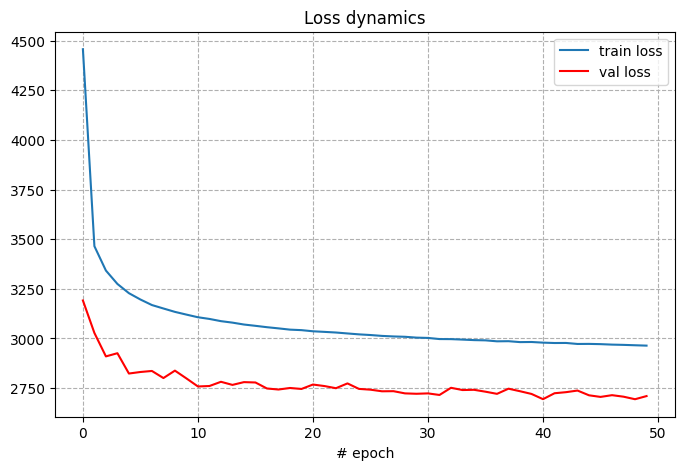

In [83]:
plot_loss(train_losses, val_losses, num_epochs)

In [84]:
# < тут Ваш код: выведите первые Х картинок и их реконструкций из val выборки на экран>

autoencoder.eval()
with torch.no_grad():
    for X_batch, y_batch in tqdm(test_loader):
        X_batch = X_batch.to(device)
        y_batch = y_batch.to(device)

        mu, logsigma, reconstruction = autoencoder(X_batch, y_batch)
        result = reconstruction
        ground_truth = X_batch

  0%|          | 0/313 [00:00<?, ?it/s]

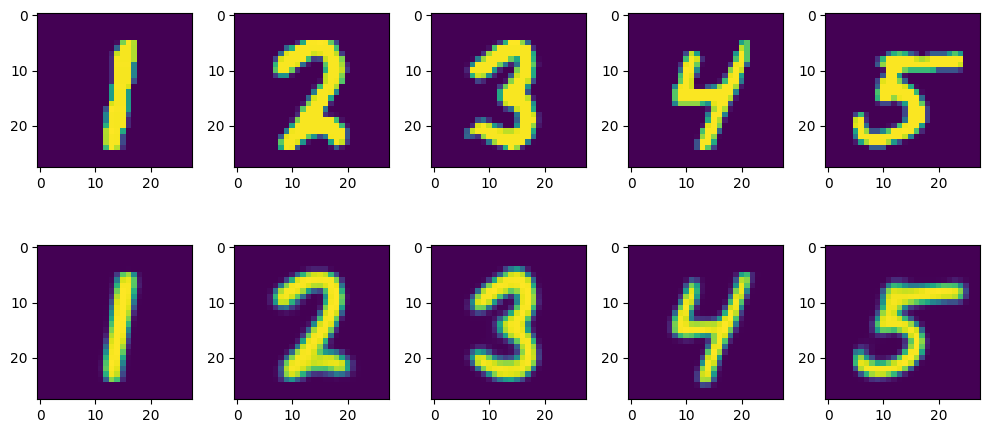

In [85]:
plot_examples(torch.cat([ground_truth[:5], result[:5]]), ncols=5, nrows=2)

### Sampling


Тут мы будем сэмплировать из CVAE. Это прикольнее, чем сэмплировать из простого AE/VAE: тут можно взять один и тот же латентный вектор и попросить CVAE восстановить из него картинки разных классов!
Для MNIST вы можете попросить CVAE восстановить из одного латентного вектора, например, картинки цифры 5 и 7.

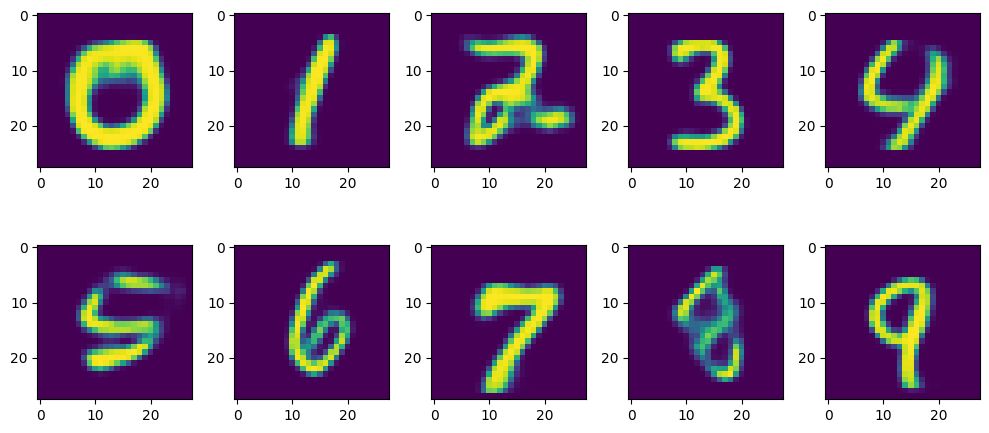

In [92]:
# <тут нужно научиться сэмплировать из декодера цифры определенного класса>

z = np.array([np.random.normal(0, 1, latent_dim) for i in range(10)])
z = torch.tensor(z, device=device, dtype=torch.float)
target = np.arange(10)
target = torch.tensor(target, device=device, dtype=torch.long)
output = autoencoder.decode(z, target)

# <выведите тут полученные картинки>
plot_examples(output, ncols=5, nrows=2)

Splendid! Вы великолепны!


### Latent Representations

Давайте посмотрим, как выглядит латентное пространство картинок в CVAE и сравним с картинкой для VAE =)

Опять же, нужно покрасить точки в разные цвета в зависимости от класса.

In [107]:
# <ваш код получения латентных представлений, применения TSNE и визуализации>

all_latents = []
all_targets = []

autoencoder.eval()

with torch.no_grad():
    for X_batch, y_batch in tqdm(test_loader):
        X_batch = X_batch.to(device)
        y_batch = y_batch.to(device)
        
        mu, logsigma, reconstruction = autoencoder(X_batch, y_batch)
        
        latent_vec = torch.randn(latent_dim, device=device)
        std = torch.exp(logsigma)
        latent_vec = std * latent_vec + mu
        all_latents.append(latent_vec.detach().cpu())
        all_targets.append(y_batch.detach().cpu())

all_latents = torch.cat(all_latents, dim=0).numpy()
all_targets = torch.cat(all_targets, dim=0).numpy()

  0%|          | 0/313 [00:00<?, ?it/s]

In [108]:
tsne = TSNE(n_components=2, perplexity=7, random_state=42)
all_latents_emb = tsne.fit_transform(all_latents)

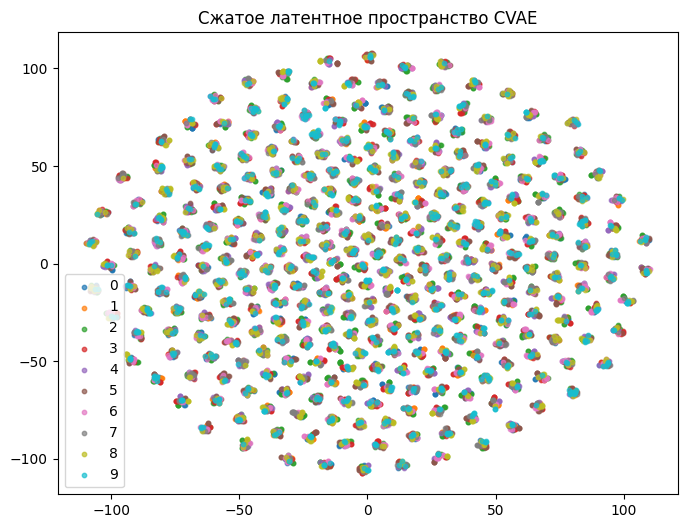

In [119]:
plt.figure(figsize=(8, 6))
plt.title('Сжатое латентное пространство СVAE')

classes = np.unique(all_targets)
for cls in classes:
    idx = all_targets == cls
    plt.scatter(all_latents_emb[idx, 0], all_latents_emb[idx, 1], label=f"{cls}", s=10, alpha=0.7)

plt.legend()
plt.show()

Что вы думаете насчет этой картинки? Отличается от картинки для VAE?

# BONUS 1: Denoising (2 балла)

## Внимание! За бонусы доп. баллы не ставятся, но вы можете сделать их для себя.

У автоэнкодеров, кроме сжатия и генерации изображений, есть другие практические применения. Про одно из них эта бонусная часть задания.

Автоэнкодеры могут быть использованы для избавления от шума на фотографиях (denoising). Для этого их нужно обучить специальным образом: input картинка будет зашумленной, а выдавать автоэнкодер должен будет картинку без шума.
То есть, loss-функция AE останется той же (MSE между реальной картинкой и выданной), а на вход автоэнкодеру будет подаваться зашумленная картинка.

<a href="https://ibb.co/YbRJ1nZ"><img src="https://i.ibb.co/0QD164t/Screen-Shot-2020-06-04-at-4-49-50-PM.png" alt="Screen-Shot-2020-06-04-at-4-49-50-PM" border="0"></a>

Для этого нужно взять ваш любимый датасет (датасет лиц из первой части этого задания или любой другой) и сделать копию этого датасета с шумом.

В питоне шум можно добавить так:

In [ ]:
noise_factor = 0.5
X_noisy = X + noise_factor * np.random.normal(loc=0.0, scale=1.0, size=X.shape)

In [ ]:
<тут ваш код обучения автоэнкодера на зашумленных картинках. Не забудьте разбить на train/test!>

In [ ]:
<тут проверка, как AE убирает шум с тестовых картинок. Надеюсь, все получилось =)>

# BONUS 2: Image Retrieval (2 балла)

## Внимание! За бонусы доп. баллы не ставятся, но вы можете сделать их для себя.

Давайте представим, что весь наш тренировочный датасет -- это большая база данных людей. И вот мы получили картинку лица какого-то человека с уличной камеры наблюдения (у нас это картинка из тестового датасета) и хотим понять, что это за человек. Что нам делать? Правильно -- берем наш VAE, кодируем картинку в латентное представление и ищем среди латентных представлений лиц нашей базы самые ближайшие!

План:

1. Получаем латентные представления всех лиц тренировочного датасета
2. Обучаем на них LSHForest `(sklearn.neighbors.LSHForest)`, например, с `n_estimators=50`
3. Берем картинку из тестового датасета, с помощью VAE получаем ее латентный вектор
4. Ищем с помощью обученного LSHForest ближайшие из латентных представлений тренировочной базы
5. Находим лица тренировочного датасета, которым соответствуют ближайшие латентные представления, визуализируем!

Немного кода вам в помощь: (feel free to delete everything and write your own)

In [ ]:
codes = <поучите латентные представления картинок из трейна>

In [ ]:
# обучаем LSHForest
from sklearn.neighbors import LSHForest
lshf = LSHForest(n_estimators=50).fit(codes)

In [ ]:
def get_similar(image, n_neighbors=5):
  # функция, которая берет тестовый image и с помощью метода kneighbours у LSHForest ищет ближайшие векторы
  # прогоняет векторы через декодер и получает картинки ближайших людей

  code = <получение латентного представления image>

  (distances,),(idx,) = lshf.kneighbors(code, n_neighbors=n_neighbors)

  return distances, X_train[idx]

In [ ]:
def show_similar(image):

  # функция, которая принимает тестовый image, ищет ближайшие к нему и визуализирует результат

    distances,neighbors = get_similar(image,n_neighbors=11)

    plt.figure(figsize=[8,6])
    plt.subplot(3,4,1)
    plt.imshow(image.cpu().numpy().transpose([1,2,0]))
    plt.title("Original image")

    for i in range(11):
        plt.subplot(3,4,i+2)
        plt.imshow(neighbors[i].cpu().numpy().transpose([1,2,0]))
        plt.title("Dist=%.3f"%distances[i])
    plt.show()

In [ ]:
<тут выведите самые похожие лица к какому-нибудь лицу из тестовой части датасета>